# 03b — Encoder trained on all training rows

Same model and code as **03**, but fine-tuned for 1 epoch on **all ~245k train rows outside the fixed val split** (03 used a 40k sample, 2 epochs). Compares head+tail vs chunk averaging, and saves **window-level prediction statistics** (how much the per-window prediction varies inside a text) as stacking features for 04.

**Run on Kaggle**
1. *Create → New Notebook → File → Import Notebook* → upload this file.
2. *Settings*: Accelerator **GPU T4 x2**, Internet **On** (downloads Hugging Face weights).
3. *Add Input*: competition **ai-generated-text-detection-hw3-ucu-ai-2026**, and the output of your **02_baseline** notebook (*Add Input → Your Work → Notebooks*).
4. *Save Version → Save & Run All (Commit)*. **ETA: ~8–9 h (training ≈ 6.5 h, inference ≈ 1.5 h; within the 12 h session limit).**

**Copy back into the repo** (from the version's *Output* tab):
- this notebook with outputs → `notebooks/03b_encoder_full.ipynb`
- `encoder_full_results.csv`, `encoder_full_loss.png`, `cm_*.png` → `reports/` and `reports/figures/`
- keep `encoder_full_model/` and `encoder_full_*_logits.csv` only on Kaggle (inputs of 04/05)


In [1]:
import os, glob, re, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SMOKE = bool(os.environ.get('SMOKE'))  # tiny local dry-run of the whole notebook; never set on Kaggle
OUT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
OUT.mkdir(exist_ok=True)
SEED, LABELS = 42, ['human', 'ai', 'fusion']
L2I = {l: i for i, l in enumerate(LABELS)}

def find(name):
    """Locate an input file in attached Kaggle inputs (or ../data locally)."""
    for root in ['/kaggle/input', '../data', str(OUT)]:
        hits = sorted(glob.glob(f'{root}/**/{name}', recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{name} not found: attach the inputs listed at the top of this notebook')

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")  # the competition metric

def report(y_true, y_pred, title):
    """Per-class metrics + normalized confusion matrix (labels are class indices)."""
    print(f'{title}: macro-F1 = {macro_f1(y_true, y_pred):.4f}')
    print(classification_report(y_true, y_pred, target_names=LABELS, digits=4))
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', values_format='.3f')
    plt.title(title); plt.grid(False)
    plt.savefig(OUT / f"cm_{re.sub(r'[^a-z0-9]+', '_', title.lower())}.png", dpi=120, bbox_inches='tight'); plt.show()

def f1_by(df, pred_col, by):
    return df.groupby(by).apply(lambda d: macro_f1(d.y, d[pred_col])).round(4).rename('macro_f1').to_frame().join(df[by].value_counts().rename('n'))

train = pd.read_csv(find('train.csv'))
test = pd.read_csv(find('test.csv'))
sub = pd.read_csv(find('sample_submission.csv'))
if SMOKE:
    test = test.head(300); sub = sub[sub.id.isin(test.id)]
train['y'] = train.label.map(L2I)
print(train.shape, test.shape)

(272352, 6) (25000, 4)


In [2]:
split = pd.read_csv(find('split.csv'))
train = train.merge(split, on='id', validate='1:1')
val = train[train.is_val].reset_index(drop=True)
print('val rows:', len(val), '| fixed train sample:', (train.sample_rank >= 0).sum())

val rows: 27451 | fixed train sample: 60001


In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

MODEL = 'hf-internal-testing/tiny-random-deberta-v2' if SMOKE else 'microsoft/mdeberta-v3-base'
MAX_LEN, STRIDE, MAX_CHUNKS = 512, 384, 8  # windows of 512 tokens, 128-token overlap, at most 8 per text
EPOCHS, LR = 1, 2e-5
NAME, P = 'encoder_full', 'encf'  # output file prefix, column prefix
print(torch.cuda.device_count(), 'GPU(s)')

tr = train[~train.is_val].reset_index(drop=True)  # ALL train rows outside val
if SMOKE:
    tr = tr.head(400)
print('training rows:', len(tr))

2 GPU(s)
training rows: 244901


### Long-text strategies
- **head**: first 510 tokens.
- **head+tail**: first 255 + last 255 tokens (training input).
- **chunks**: up to 8 evenly spaced 510-token windows covering the whole text; logits averaged. Fusion texts are only *partially* rewritten, so looking at the whole text should help most there.

In [4]:
tok = AutoTokenizer.from_pretrained(MODEL)
BODY = MAX_LEN - 2
wrap = lambda x: [tok.cls_token_id] + x + [tok.sep_token_id]
def head(ids): return wrap(ids[:BODY])
def head_tail(ids): return wrap(ids) if len(ids) <= BODY else wrap(ids[:BODY // 2] + ids[-(BODY - BODY // 2):])
def chunks(ids):
    if len(ids) <= BODY:
        return [wrap(ids)]
    n = min(int(np.ceil((len(ids) - BODY) / STRIDE)) + 1, MAX_CHUNKS)
    return [wrap(ids[s:s + BODY]) for s in np.linspace(0, len(ids) - BODY, n).astype(int)]

class DS(torch.utils.data.Dataset):
    def __init__(self, seqs, labels=None): self.seqs, self.labels = seqs, labels
    def __len__(self): return len(self.seqs)
    def __getitem__(self, i):
        d = {'input_ids': self.seqs[i], 'attention_mask': [1] * len(self.seqs[i])}
        if self.labels is not None:
            d['labels'] = int(self.labels[i])
        return d

def encode(texts, fn=lambda x: x, bs=5000):
    """Tokenize in batches, keeping only fn(ids) — full token lists of 245k texts would not fit in RAM."""
    texts, out = list(texts), []
    for b in range(0, len(texts), bs):
        out += [fn(x) for x in tok(texts[b:b + bs], add_special_tokens=False, truncation=False, verbose=False)['input_ids']]
    return out

t = time.time()
seq_tr, ids_va, ids_te = encode(tr.text, head_tail), encode(val.text), encode(test.text)
print(f'tokenized in {time.time() - t:.0f}s; val texts > {MAX_LEN} tokens: {np.mean([len(x) > BODY for x in ids_va]):.3f}')

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

tokenized in 319s; val texts > 512 tokens: 0.690


## Training (head+tail inputs)

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=3, id2label=dict(enumerate(LABELS)), label2id=L2I,
                                                           dtype=torch.float32)  # fp32 master weights for fp16 AMP (v5 keeps checkpoint dtype)
rng = np.random.RandomState(SEED)
mon = rng.choice(len(val), min(3000, len(val)), replace=False)  # small val subset to monitor epochs
steps = int(np.ceil(len(tr) / (8 * 2 * max(torch.cuda.device_count(), 1)))) * EPOCHS  # batch 8 x accum 2 x GPUs
args = TrainingArguments(
    output_dir='/tmp/enc', num_train_epochs=EPOCHS, learning_rate=LR, warmup_steps=int(0.1 * steps), weight_decay=0.01,
    per_device_train_batch_size=8, gradient_accumulation_steps=2, per_device_eval_batch_size=32,
    fp16=torch.cuda.is_available(), eval_strategy='steps', eval_steps=max(steps // (4 * EPOCHS), 1), save_strategy='no',
    logging_steps=100, report_to='none', seed=SEED,
    disable_tqdm=True)  # print loss lines instead of a progress bar (visible in Kaggle commit logs); eval 4x per epoch
trainer = Trainer(model=model, args=args, data_collator=DataCollatorWithPadding(tok),
                  train_dataset=DS(seq_tr, tr.y.values),
                  eval_dataset=DS([head_tail(ids_va[i]) for i in mon], val.y.values[mon]),
                  compute_metrics=lambda p: {'macro_f1': macro_f1(p.label_ids, p.predictions.argmax(-1))})
t = time.time()
trainer.train()
print(f'trained in {(time.time() - t) / 60:.0f} min')
trainer.save_model(OUT / f'{NAME}_model'); tok.save_pretrained(OUT / f'{NAME}_model')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.classifier.weight         | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
mask_predictions.dense.weight              | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
classifier.bias                            | MISSING    | 
pooler.dense.bias   

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

{'loss': '4.287', 'grad_norm': '5.88', 'learning_rate': '2.588e-06', 'epoch': '0.01307'}
{'loss': '2.954', 'grad_norm': '7.856', 'learning_rate': '5.203e-06', 'epoch': '0.02613'}
{'loss': '1.84', 'grad_norm': '31.16', 'learning_rate': '7.817e-06', 'epoch': '0.0392'}
{'loss': '1.535', 'grad_norm': '30.22', 'learning_rate': '1.043e-05', 'epoch': '0.05226'}
{'loss': '1.329', 'grad_norm': '52.46', 'learning_rate': '1.305e-05', 'epoch': '0.06533'}
{'loss': '1.339', 'grad_norm': '11.35', 'learning_rate': '1.566e-05', 'epoch': '0.0784'}
{'loss': '1.231', 'grad_norm': '48.84', 'learning_rate': '1.827e-05', 'epoch': '0.09146'}
{'loss': '1.309', 'grad_norm': '107.5', 'learning_rate': '1.99e-05', 'epoch': '0.1045'}
{'loss': '1.144', 'grad_norm': '29.53', 'learning_rate': '1.961e-05', 'epoch': '0.1176'}
{'loss': '1.15', 'grad_norm': '41.88', 'learning_rate': '1.932e-05', 'epoch': '0.1307'}
{'loss': '1.066', 'grad_norm': '15.19', 'learning_rate': '1.903e-05', 'epoch': '0.1437'}
{'loss': '1.042', 'g

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/encoder_full_model/tokenizer_config.json',
 '/kaggle/working/encoder_full_model/tokenizer.json')

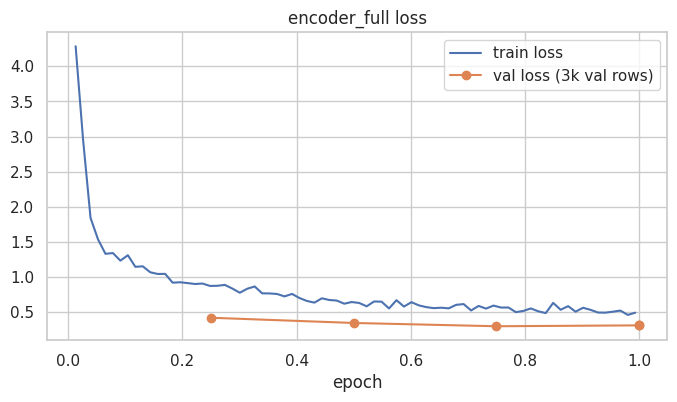

,epoch,eval_loss,eval_macro_f1
19,0.249951,0.417633,0.896634
39,0.499902,0.343322,0.912648
59,0.749853,0.296561,0.928330
79,0.999804,0.309192,0.926799
80,1.000000,0.309184,0.926799


In [6]:
log = pd.DataFrame(trainer.state.log_history)
ax = log.dropna(subset=['loss']).plot(x='epoch', y='loss', label='train loss', figsize=(8, 4))
log.dropna(subset=['eval_loss']).plot(x='epoch', y='eval_loss', marker='o', label='val loss (3k val rows)', ax=ax)
plt.title(f'{NAME} loss'); plt.savefig(OUT / f'{NAME}_loss.png', dpi=120, bbox_inches='tight'); plt.show()
log.dropna(subset=['eval_loss'])[['epoch', 'eval_loss', 'eval_macro_f1']]

**Observations.** Val macro-F1 rises at each quarter epoch (0.897 → 0.913 → 0.928) and levels off at the end (0.927). One epoch over 245k rows beats two epochs over 40k (03: 0.900): more data helps more than more epochs.

## Inference with each long-text strategy

In [7]:
def predict(seqs):
    order = np.argsort([len(s) for s in seqs])  # length-sorted batches = less padding
    out = trainer.predict(DS([seqs[i] for i in order])).predictions
    logits = np.empty_like(out); logits[order] = out
    return logits

WIN = {}  # window-level stats of the last predict_chunks call (input features for stacking in 04)
def predict_chunks(ids_list):
    owner, seqs = [], []
    for i, ids in enumerate(ids_list):
        for c in chunks(ids):
            owner.append(i); seqs.append(c)
    lg, owner = predict(seqs), np.array(owner)
    n = np.bincount(owner)
    agg = np.zeros((len(ids_list), lg.shape[1])); np.add.at(agg, owner, lg)
    # how much the per-window prediction varies: a fusion text should look human in some windows, AI in others
    pr = np.exp(lg - lg.max(1, keepdims=True)); pr /= pr.sum(1, keepdims=True)
    w = pd.DataFrame(pr, columns=LABELS).assign(o=owner).groupby('o')[LABELS].agg(['std', 'min', 'max']).fillna(0)
    w.columns = [f'{P}w_{s}_{l}' for l, s in w.columns]
    WIN['last'] = w.assign(**{f'{P}w_n': n}).reset_index(drop=True)
    return agg / n[:, None]

STRATS = {'head_tail': lambda L: predict([head_tail(x) for x in L]), 'chunks': predict_chunks}
val_logits = {}
for name, f in STRATS.items():
    t = time.time(); val_logits[name] = f(ids_va)
    print(f'{name}: val macro-F1 {macro_f1(val.y, val_logits[name].argmax(1)):.4f} ({time.time() - t:.0f}s)')
win_va = WIN['last']

head_tail: val macro-F1 0.9305 (753s)
chunks: val macro-F1 0.8935 (2030s)


## Comparison with the baseline (same val split) and overfitting check

In [8]:
bl = val[['id', 'y']].merge(pd.read_csv(find('baseline_val_scores.csv')), on='id')
rows = [{'model': 'TF-IDF baseline (02)', 'val_macro_f1': macro_f1(bl.y, bl[[f'base_{l}' for l in LABELS]].values.argmax(1))}]
rows += [{'model': f'mDeBERTa ({len(tr)} rows), {k}', 'val_macro_f1': macro_f1(val.y, v.argmax(1))} for k, v in val_logits.items()]
mon_tr = rng.choice(len(tr), min(3000, len(tr)), replace=False)
rows.append({'model': 'mDeBERTa, head_tail on 3k TRAIN rows (overfit check)', 'val_macro_f1': macro_f1(tr.y.values[mon_tr], predict([seq_tr[i] for i in mon_tr]).argmax(1))})
enc_res = pd.DataFrame(rows).round(4)
enc_res.to_csv(OUT / f'{NAME}_results.csv', index=False)
enc_res

,model,val_macro_f1
0,TF-IDF baseline (02),0.8796
1,"mDeBERTa (244901 rows), head_tail",0.9305
2,"mDeBERTa (244901 rows), chunks",0.8935
3,"mDeBERTa, head_tail on 3k TRAIN rows (overfit ...",0.9385


**Observations.** Training on all rows lifts head+tail to **0.9305** (+0.031 over 03, +0.051 over the 60k TF-IDF baseline). This is the single-model **reference** for 04. Chunk averaging is again worse (0.894), which confirms 03. The train–val gap is small (0.939 vs 0.931), so the model is not overfitting. The chunk pass is still run on val and test because its per-window min/max/std statistics are saved as stacking features; the SHAP analysis in 05 shows they are the most important ones.

best strategy: head_tail
encoder_full val (head_tail): macro-F1 = 0.9305
              precision    recall  f1-score   support

       human     0.9067    0.8620    0.8838      6723
          ai     0.9953    0.9975    0.9964     12239
      fusion     0.8955    0.9277    0.9113      8489

    accuracy                         0.9427     27451
   macro avg     0.9325    0.9290    0.9305     27451
weighted avg     0.9427    0.9427    0.9425     27451



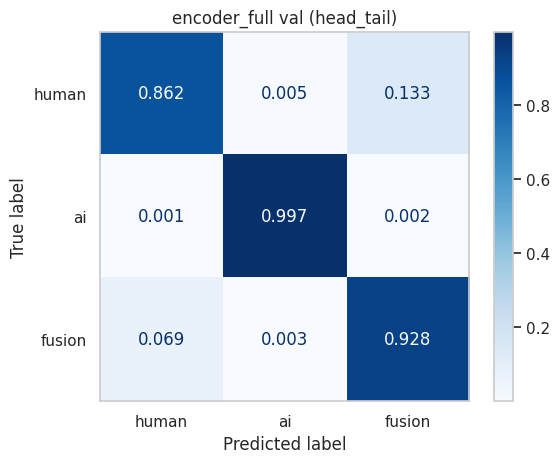

,macro_f1,n
lang,,
de-DE,0.9169,5383
en-EN,0.9341,22068


,macro_f1,n
domain,,
arxiv_papers,0.7661,1378
blog_authorship_corpus,0.8794,4004
bundestag,0.9169,5343
cnn_news,0.9681,4436
euro_court_cases,0.8634,2776
gutenberg,0.8305,723
house_of_commons,0.9539,3117
student_essays,0.9722,5674


In [9]:
BEST = max(val_logits, key=lambda k: macro_f1(val.y, val_logits[k].argmax(1)))
print('best strategy:', BEST)
val['pred'] = val_logits[BEST].argmax(1)
report(val.y, val.pred, f'{NAME} val ({BEST})')
display(f1_by(val, 'pred', 'lang'), f1_by(val, 'pred', 'domain'))

**Observations.** Per class: ai 0.996, fusion 0.911, human 0.884. The main error is now human texts predicted as fusion (human recall 0.862). English is now better than German (0.934 vs 0.917), the reverse of TF-IDF. arxiv (0.77) and gutenberg (0.83) are still the weakest domains.

## Test predictions, saved logits, submission

In [10]:
test_chunks = predict_chunks(ids_te); win_te = WIN['last']  # window stats are needed for stacking either way
test_logits = test_chunks if BEST == 'chunks' else STRATS[BEST](ids_te)
cols = [f'{P}_{l}' for l in LABELS]
pd.concat([pd.DataFrame(val_logits[BEST], columns=cols), win_va], axis=1).assign(id=val.id.values).to_csv(OUT / f'{NAME}_val_logits.csv', index=False)
pd.concat([pd.DataFrame(test_logits, columns=cols), win_te], axis=1).assign(id=test.id.values).to_csv(OUT / f'{NAME}_test_logits.csv', index=False)

pred = pd.DataFrame({'id': test.id, 'label': np.array(LABELS)[test_logits.argmax(1)]})
submission = sub[['id']].merge(pred, on='id', how='left')
assert len(submission) == len(sub) and submission.label.isin(LABELS).all()
submission.to_csv(OUT / f'submission_{NAME}.csv', index=False)
print(submission.label.value_counts(normalize=True).round(3))

label
ai        0.515
fusion    0.249
human     0.236
Name: proportion, dtype: float64
